In [1]:
options(repr.plot.width = 5, repr.plot.height = 3, repr.plot.res = 250)

In [2]:
library('tidymodels')

gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

── Attaching packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


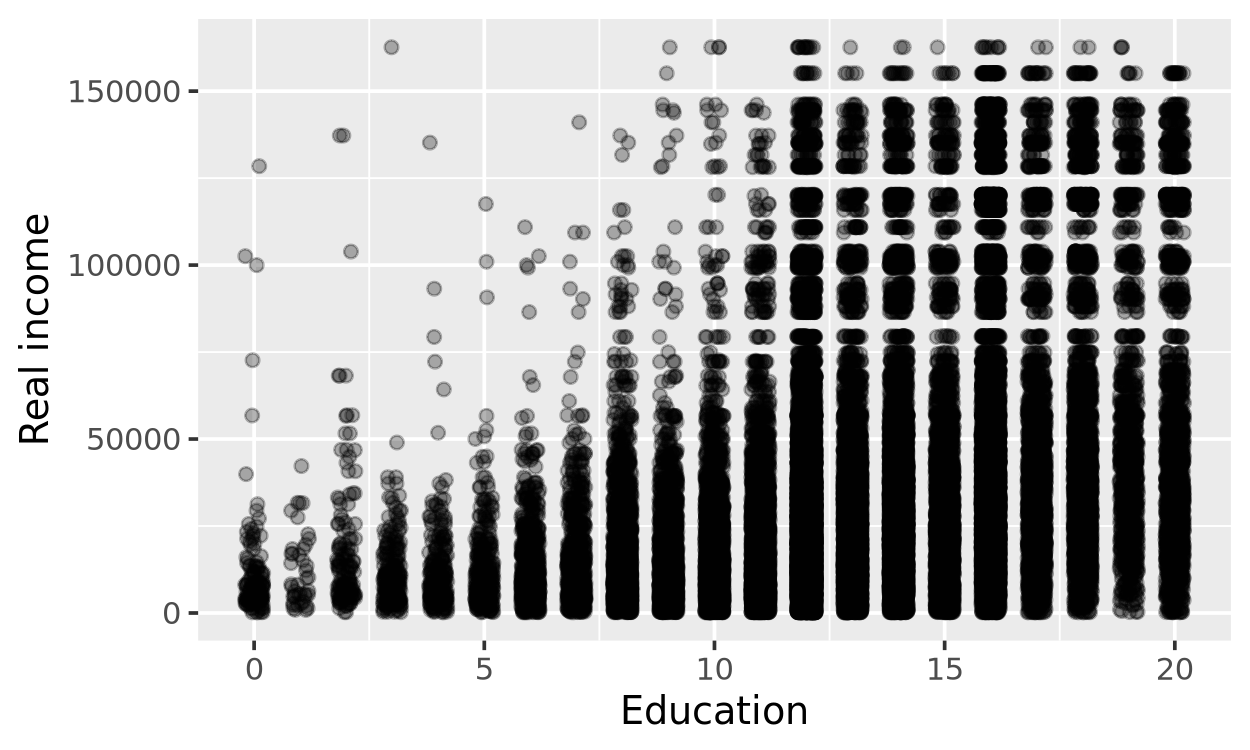

In [3]:
gss |>
  ggplot(aes(x = educ, y = realinc)) +
  geom_point(alpha = 0.3, position = position_jitter(width = 0.2, height = 0.2)) +
  labs(x = "Education", y = "Real income")

In [4]:
set.seed(512)

n_models <- 100

param_grid <- tibble(
  .model    = 1:n_models,
  intercept = runif(n_models, min = -50000, max = 100000),
  slope     = runif(n_models, min = -5000,  max = 10000)
)

param_grid |> glimpse()

Rows: 100
Columns: 3
$ .model    <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> 7799.908, -29920.001, 18513.888, 89865.118, 46562.336, -2039…
$ slope     <dbl> 5052.65701, 8970.66775, 2019.70081, 2908.19613, 9689.15344, …


In [5]:
# predictor
# feature
# regressor

Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


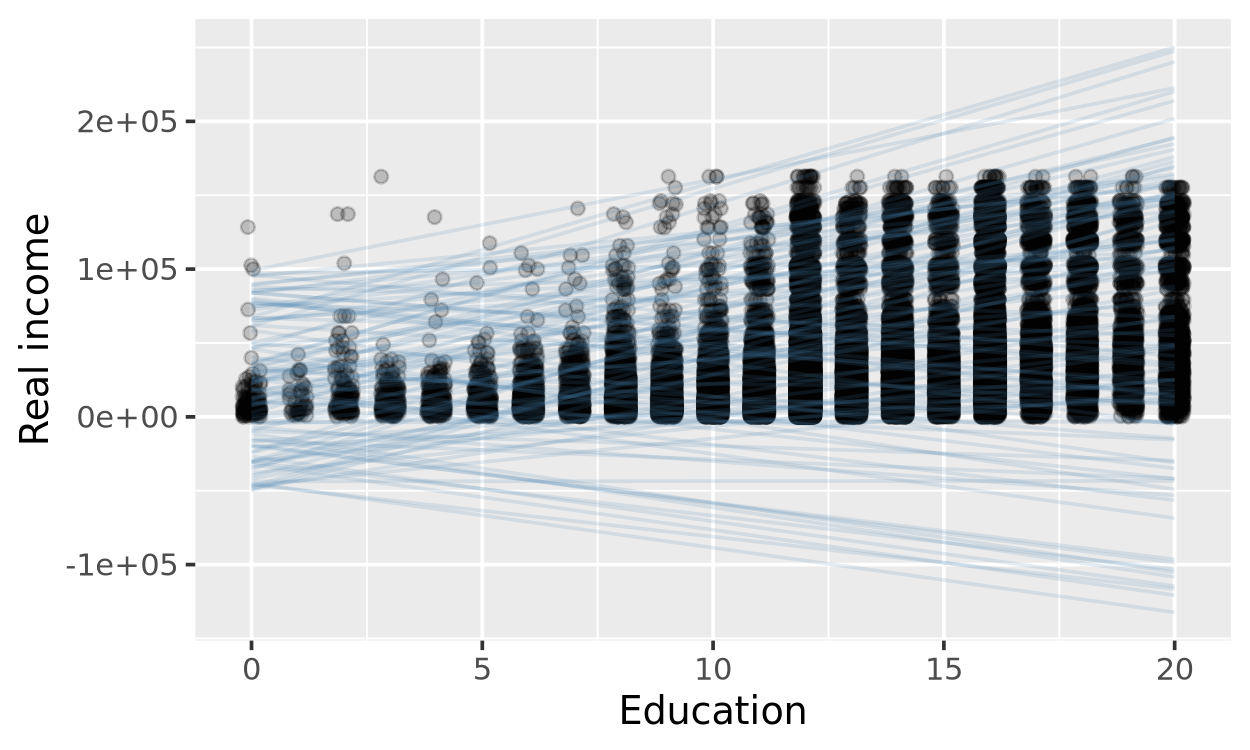

In [6]:
educ_seq <- tibble(educ = seq(0, 20, length.out = 100))

model_lines <- param_grid |>
  crossing(educ_seq) |>
  mutate(realinc = intercept + slope * educ)

gss |>
  ggplot(aes(x = educ, y = realinc)) +
  geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2)) +
  geom_line(
    data = model_lines,
    aes(group = .model),
    color = "steelblue",
    alpha = 0.15
  ) +
  labs(x = "Education", y = "Real income")

Steps for creating a model: 

1. Pick the model form: 
   $$\text{realinc} = \intercept + \slope \cdot \text{educ}$$
3. Design a way to evaluate different model parameters
4. Optimize our parameter values

In [7]:
calc_rmse <- function(intercept, slope, data = gss) {
  preds <- intercept + slope * data$educ
  sqrt(mean((data$realinc - preds)^2, na.rm = TRUE))
}

# Example: score a single parameter combination
calc_rmse(intercept = -20000, slope = 4000)

[1] 28331.55

In [8]:
intercept = 20000
slope = 10000

preds <- intercept + slope * gss$educ
sqrt(mean((gss$realinc - preds)^2, na.rm = TRUE))

[1] 123947

In [9]:
param_grid <- param_grid |>
  mutate(rmse = map2_dbl(intercept, slope, calc_rmse))

param_grid |>
  arrange(rmse) |>
  glimpse()

Rows: 100
Columns: 4
$ .model    <int> 16, 77, 17, 3, 59, 28, 41, 74, 78, 15, 93, 85, 24, 23, 52, 3…
$ intercept <dbl> -4128.912, -41808.412, -30405.522, 18513.888, -29864.252, 13…
$ slope     <dbl> 2644.13497, 5493.92419, 3917.73660, 2019.70081, 5799.62409, …
$ rmse      <dbl> 28516.55, 29017.64, 30543.30, 31333.01, 32280.78, 32301.25, …


Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


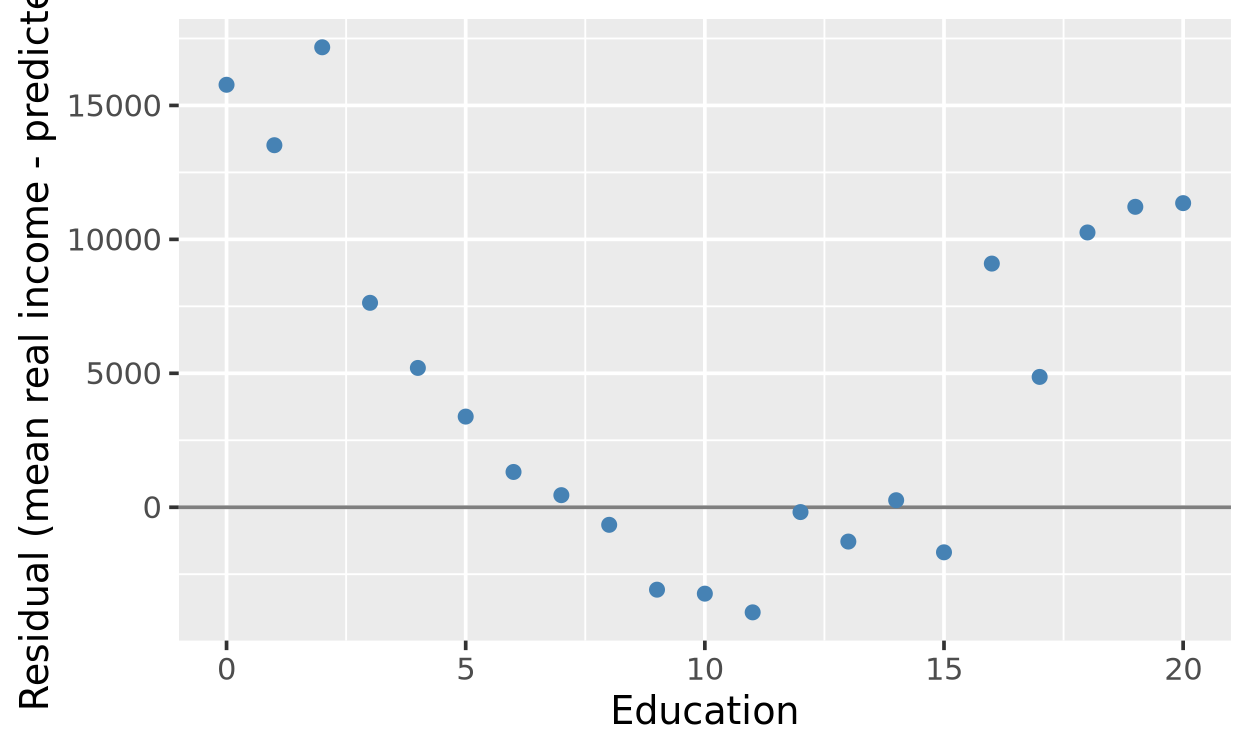

In [10]:
# Use the best-fitting combo so far (change this to inspect any other combo)
fit <- param_grid |> slice_min(rmse, n = 1)

gss_by_educ <- gss |>
  group_by(educ) |>
  summarise(mean_realinc = mean(realinc, na.rm = TRUE), .groups = "drop") |>
  mutate(
    predicted = fit$intercept + fit$slope * educ,
    residual  = mean_realinc - predicted
  )

gss_by_educ |>
  ggplot(aes(x = educ, y = residual)) +
  geom_hline(yintercept = 0, color = "grey50") +
  geom_point(color = "steelblue") +
  labs(x = "Education", y = "Residual (mean real income - predicted)")

In [11]:
# What values for slope and intercept minimize RMSE?

## Algorithm - Random search

1. Give me some random slope and intercept values
2. Calculate RMSE for all combos
3. Find the best line
4. Now we have a slope and intercept for the model 

## Algorithm - Grid search

1. Give me some grid of slope and intercept values
2. Calculate RMSE for all combos
3. Find the best line
4. Now we have a slope and intercept for the model 

In [13]:
expand_grid(
    a = c(1, 2, 3), 
    b = c('a', 'b', 'c')
    )|> display()

a,b
<dbl>,<chr>
1,a
1,b
1,c
2,a
2,b
2,c
3,a
3,b
3,c


In [19]:
grid <- expand_grid(
    slope = seq(-25000, -5000, length = 25),
    intercept = seq(2500, 4500, length = 25)
) |>
    mutate(dist = map2_dbl(slope, intercept, calc_rmse))

grid |> head()

  slope  intercept dist    
1 -25000 2500.000  37702.02
2 -25000 2583.333  36970.70
3 -25000 2666.667  36259.68
4 -25000 2750.000  35570.16
5 -25000 2833.333  34903.42
6 -25000 2916.667  34260.79

In [ ]:
# seq(-25000, -5000, length = 25)
# gives us a list of integers from -25000 to -5000 with exactly 25 integers

# The use of the AI agent makes the way each command is written not uniform; I can't follow along in lecture because of the differing names for
# variables/functions. I don't think that it is good to use AI to build our models while we are still in a period where we need to so actively
# follow along in order to know what is happening where.

In [ ]:
slope = some forumla
int = some formula 

## Tidymodels

In [21]:
mod = linear_reg()
mod 

# mod = logistic_reg()
# mod = rand_forest()

Linear Regression Model Specification (regression)

Computational engine: lm 


In [22]:
mod_fit = mod |> fit(realinc ~ educ, data = gss) 
mod_fit

# 'fit' means find the optimal parameter values
# formula syntax
# the slope is educ because of the formula we wrote in the Markdown cell (slope is multiplied by educ)

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14472         3576  


## Marginal effect

The marginal effect of education on income is $3,576 

Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


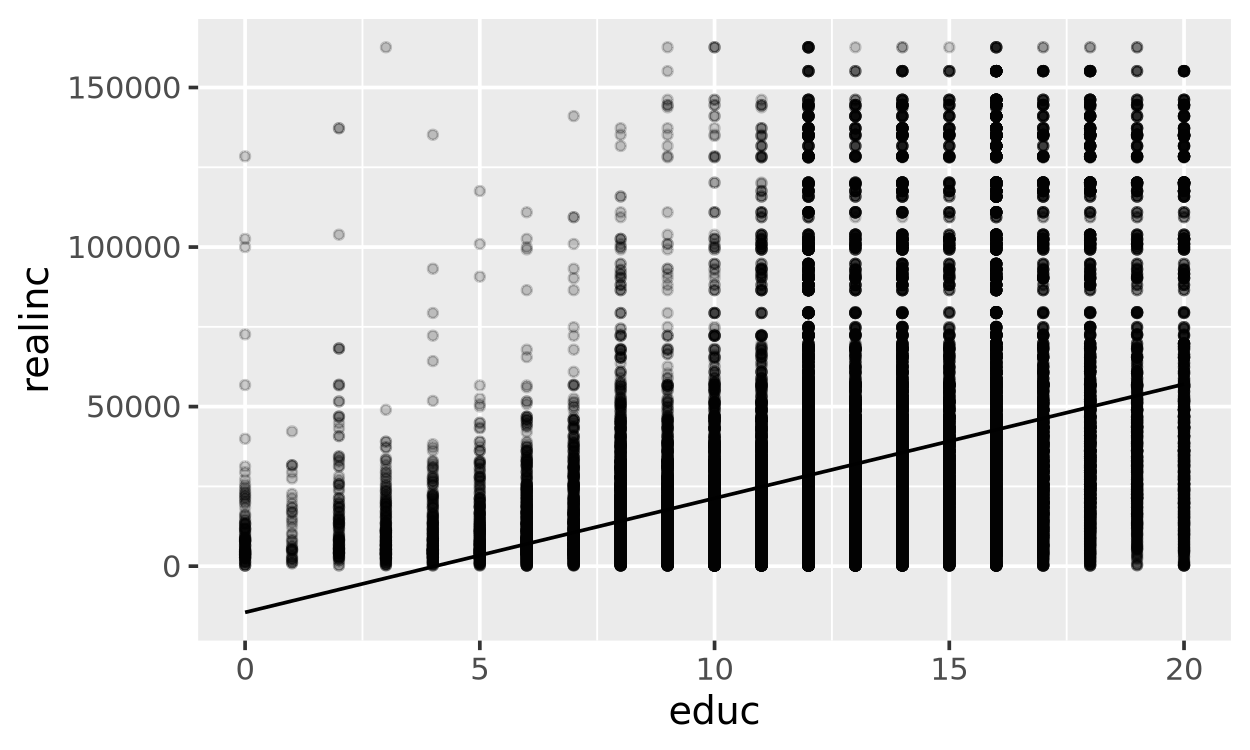

In [30]:
predict(mod_fit, gss) |> bind_cols(gss) |>
ggplot(aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, size = 1) + 
    geom_line(aes(y = .pred))

Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


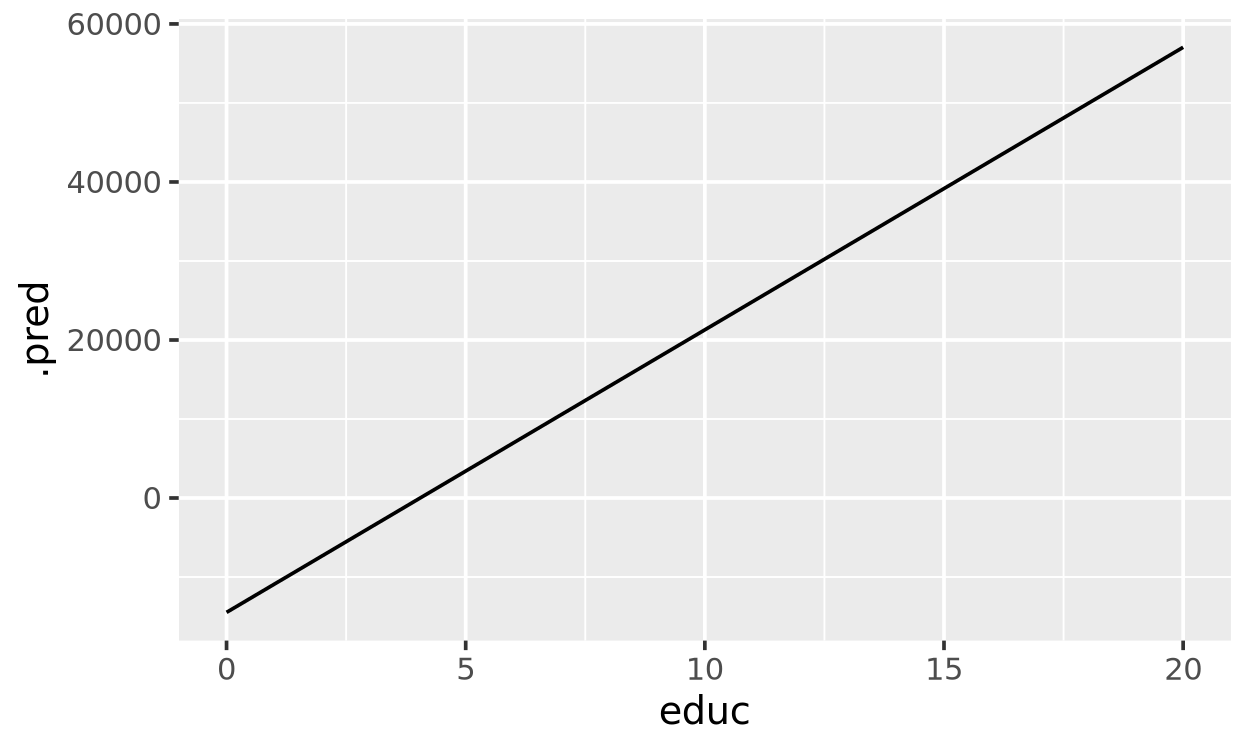

In [27]:
predict(mod_fit, gss) |> bind_cols(gss) |>
ggplot(aes(x = educ, y = .pred)) + geom_line()

In [32]:
gss2 = gss |>
    mutate(educ_squared = educ^2)
gss2 |> head()

  year id age educ sex gunlaw grass realinc educ_squared
1 1972 1  23  16   2   1      NA    18951   256         
2 1972 2  70  10   1   1      NA    24366   100         
3 1972 3  48  12   2   1      NA    24366   144         
4 1972 4  27  17   2   1      NA    30458   289         
5 1972 5  61  12   2   1      NA    50763   144         
6 1972 6  26  14   1   2      NA    43994   196         

In [33]:
mod_fit = mod |> fit(realinc ~ educ + educ_squared, data = gss2) 
mod_fit

parsnip model object


Call:
stats::lm(formula = realinc ~ educ + educ_squared, data = data)

Coefficients:
 (Intercept)          educ  educ_squared  
     10802.2        -729.6         171.4  


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 286 rows containing missing values or values outside the scale range (`geom_line()`).”


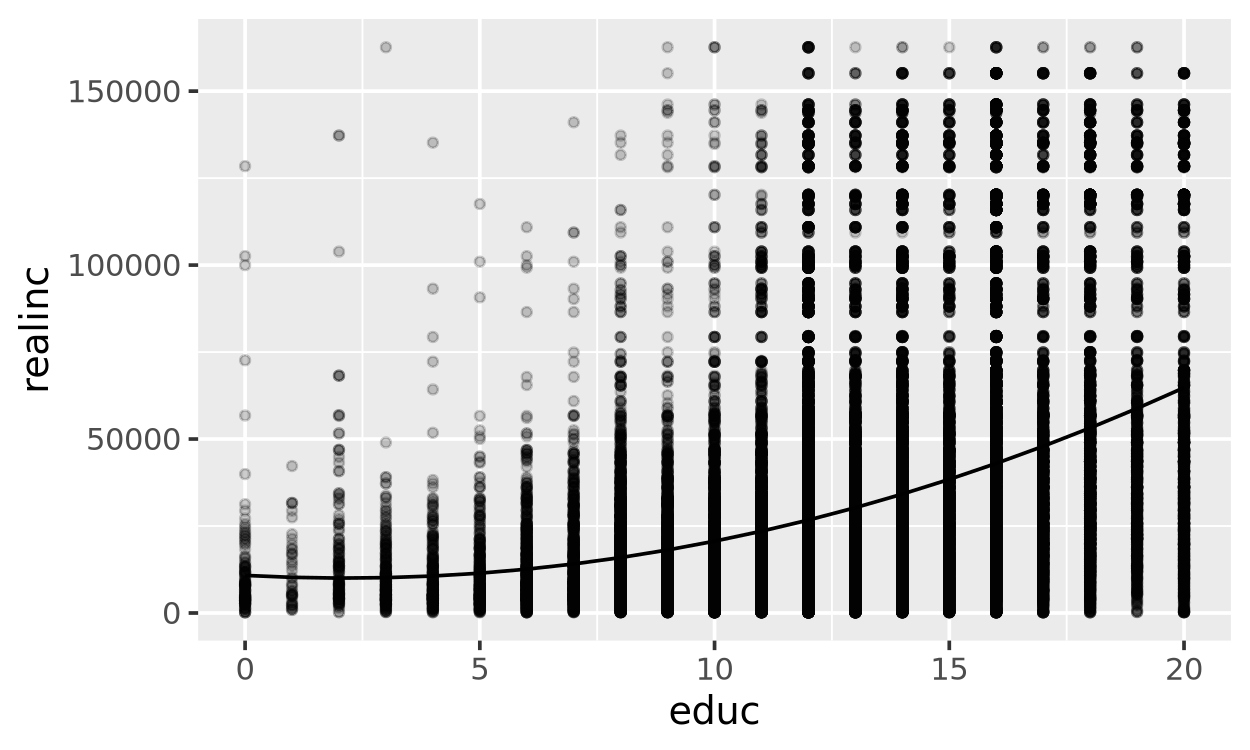

In [34]:
predict(mod_fit, gss2) |> bind_cols(gss2) |>
ggplot(aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, size = 1) + 
    geom_line(aes(y = .pred))